<a href="https://colab.research.google.com/github/iqbal-prayogi/Klasifikasi/blob/main/Klasifikasi_Angka_Tulisan_Tangan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Angka Tulisan Tangan (*Handwritten Digit Recognition*) dengan Support Vector Machine


## 1. Permasalahan yang Dihadapi

### 1.1 Latar belakang
Layanan pos, perbankan, dan administrasi pemerintahan menerima jutaan dokumen tulisan tangan setiap hari, misalnya **kode pos pada amplop surat**, **nominal angka pada cek bank**, dan **isian angka pada formulir** (nomor induk, tanggal, jumlah). Informasi tersebut harus diubah menjadi data digital agar dapat diproses oleh sistem komputer.

Jika dilakukan secara manual oleh petugas, proses ini:
- **lambat**, karena volume dokumen sangat besar;
- **mahal**, karena membutuhkan banyak tenaga kerja;
- **rawan kesalahan**, karena petugas bisa lelah atau salah membaca tulisan yang kurang jelas. Salah baca satu angka pada kode pos membuat surat nyasar, dan salah baca nominal cek merugikan nasabah atau bank.

### 1.2 Tantangan teknis
Mengenali angka tulisan tangan tidak semudah mengenali angka cetak, karena:
- gaya tulisan tiap orang berbeda (tebal-tipis, miring, besar-kecil);
- beberapa angka bentuknya mirip, misalnya **1 dan 7**, **4 dan 9**, serta **3, 5, dan 8**;
- ada gangguan (*noise*) seperti coretan atau goresan yang tidak rata.

Menulis aturan manual (*if-else*) untuk semua variasi tersebut hampir mustahil. Machine Learning menjawab masalah ini karena model **belajar sendiri dari ribuan contoh gambar yang sudah berlabel**.

### 1.3 Rumusan masalah klasifikasi
Diberikan sebuah gambar angka tulisan tangan berukuran 8×8 piksel (64 nilai intensitas), tentukan angka (0 sampai 9) yang ditulis.

- **Jenis tugas:** klasifikasi **multikelas** (10 kelas)
- **Input (fitur):** 64 nilai piksel
- **Output (label):** angka 0, 1, 2, ..., 9
- **Tujuan:** membangun model dengan tingkat kesalahan baca sekecil mungkin

## 2. Metode Klasifikasi yang Digunakan

### 2.1 Support Vector Machine (SVM)
Metode utama yang digunakan adalah **Support Vector Machine (SVM)** dengan kernel **RBF (*Radial Basis Function*)**. SVM diperkenalkan oleh Cortes dan Vapnik (1995).

**Gagasan dasar.** SVM mencari **batas pemisah (*hyperplane*)** antara dua kelas dengan **margin terbesar**, yaitu jarak terjauh antara batas tersebut dengan data terdekat dari masing-masing kelas. Data terdekat itu disebut ***support vector***. Batas dengan margin besar cenderung lebih baik dalam mengenali data baru.

**Kernel RBF.** Data piksel gambar tidak dapat dipisahkan dengan garis lurus. Kernel RBF memetakan data ke ruang berdimensi lebih tinggi sehingga batas pemisah yang melengkung dapat dibentuk:

$$K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma \, \lVert \mathbf{x} - \mathbf{x}' \rVert^{2}\right)$$

**Hyperparameter penting:**
- **C** adalah penalti kesalahan. Nilai besar membuat model berusaha mengklasifikasikan data latih sebaik mungkin, tetapi berisiko *overfitting*. Nilai kecil membuat batas lebih halus.
- **gamma (γ)** menentukan jangkauan pengaruh satu data latih. Nilai besar membuat batas sangat rumit dan lokal, sedangkan nilai kecil membuat batas lebih halus.

**Klasifikasi multikelas.** SVM pada dasarnya memisahkan dua kelas. Untuk 10 kelas, implementasi `SVC` di scikit-learn memakai strategi ***one-vs-one***: dibangun satu SVM untuk setiap pasang kelas (45 pasang), lalu hasil akhirnya ditentukan lewat *voting*.

### 2.2 Alasan memilih SVM
- Bekerja baik pada data **berdimensi tinggi** seperti piksel gambar.
- Kernel RBF mampu menangkap pola **non-linear**.
- Secara historis menjadi salah satu metode yang sangat kuat untuk pengenalan digit.
- Hanya memiliki sedikit hyperparameter sehingga mudah dioptimalkan dengan *Grid Search*.

### 2.3 Metode pembanding
Hasil SVM dibandingkan dengan empat metode klasifikasi lain:

| Metode | Prinsip singkat |
|---|---|
| **Random Forest** | Gabungan banyak pohon keputusan, hasil akhir lewat *voting* mayoritas (Breiman, 2001) |
| **Decision Tree** | Satu pohon keputusan berbasis aturan percabangan |
| **K-Nearest Neighbors (KNN)** | Kelas ditentukan dari mayoritas K tetangga terdekat |
| **Logistic Regression** | Model linear yang menghitung probabilitas tiap kelas |

### 2.4 Metrik evaluasi
Karena ada 10 kelas, presisi, *recall*, dan F1-score dihitung per kelas lalu dirata-rata (***macro average***), sehingga setiap angka diperlakukan sama penting.

- **Akurasi** = jumlah prediksi benar / seluruh data uji
- **Presisi** = TP / (TP + FP). Dari semua yang diprediksi sebagai suatu angka, berapa yang benar.
- **Recall** = TP / (TP + FN). Dari semua gambar angka tertentu, berapa yang berhasil dikenali.
- **F1-score** = rata-rata harmonik presisi dan recall
- ***Confusion matrix*** menunjukkan angka mana yang sering tertukar dengan angka lain.

## 3. Dataset

### 3.1 Identitas dataset

| Aspek | Keterangan |
|---|---|
| **Nama** | Optical Recognition of Handwritten Digits (sering disebut *optdigits*) |
| **Pembuat** | E. Alpaydin dan C. Kaynak, Department of Computer Engineering, Bogazici University, Istanbul, Turki |
| **Tahun donasi** | 1998 |
| **Sumber asli** | UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits |
| **DOI** | https://doi.org/10.24432/C50P49 |
| **Lisensi** | Creative Commons Attribution 4.0 International (CC BY 4.0) |
| **Sumber yang dipakai di notebook ini** | Fungsi `load_digits()` pada `scikit-learn`, yang merupakan salinan **bagian data uji** dari dataset UCI di atas |
| **Jumlah data (versi scikit-learn)** | 1.797 gambar |
| **Jumlah fitur** | 64 (piksel dari gambar 8×8) |
| **Nilai fitur** | Bilangan bulat 0 sampai 16 (semakin besar, semakin gelap) |
| **Jumlah kelas** | 10 (angka 0 sampai 9) |
| **Missing value** | Tidak ada |

### 3.2 Proses pembentukan data
Menurut dokumentasi UCI, tulisan tangan dikumpulkan dari **43 orang** pada formulir cetak. Sebanyak 30 orang menyumbang data latih dan 13 orang lainnya menyumbang data uji. Program pengolah gambar dari **NIST** (*National Institute of Standards and Technology*) dipakai untuk mengekstrak gambar angka berukuran 32×32 piksel. Gambar tersebut dibagi menjadi blok 4×4 tanpa tumpang tindih, lalu jumlah piksel hitam di tiap blok dihitung. Hasilnya adalah matriks **8×8 dengan nilai 0 sampai 16**. Cara ini mengurangi dimensi data dan membuat model lebih tahan terhadap distorsi kecil.

Dataset UCI lengkap berisi 5.620 gambar (3.823 data latih dan 1.797 data uji). Notebook ini memakai **1.797 data** versi `scikit-learn`, lalu membaginya kembali menjadi data latih dan data uji pada Tahap 4.

### 3.3 Sumber
- Alpaydin, E., & Kaynak, C. (1998). *Optical Recognition of Handwritten Digits* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50P49
- Dokumentasi scikit-learn: https://scikit-learn.org/stable/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset

## 4. Tahapan Penerapan

Tahapan yang dijalankan secara berurutan:

| Tahap | Kegiatan |
|---|---|
| 0 | Import library |
| 1 | Pengumpulan data |
| 2 | Eksplorasi data (EDA) |
| 3 | Pra-pemrosesan data |
| 4 | Pembagian data latih dan data uji |
| 5 | Normalisasi fitur |
| 6 | Pelatihan model dan optimasi hyperparameter |
| 7 | Evaluasi model |
| 8 | Analisis kesalahan prediksi |
| 9 | Perbandingan dengan model lain |
| 10 | Contoh penggunaan model (demo prediksi) |

### Tahap 0. Import Library
**Tujuan:** memuat semua library yang diperlukan dan mencatat versinya agar hasil dapat direproduksi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from collections import Counter

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

print("Versi scikit-learn:", sklearn.__version__)
print("Versi pandas      :", pd.__version__)
print("Versi numpy       :", np.__version__)

Versi scikit-learn: 1.6.1
Versi pandas      : 2.2.3
Versi numpy       : 2.1.3


### Tahap 1. Pengumpulan Data
**Tujuan:** memuat dataset *Optical Recognition of Handwritten Digits* dan memeriksa dokumentasi sumber datanya. Setiap gambar berukuran 8×8 piksel diratakan menjadi 64 fitur. Label adalah angka 0 sampai 9.

In [2]:
digits = load_digits()

X = pd.DataFrame(digits.data, columns=[f"pixel_{i}" for i in range(64)])
y = pd.Series(digits.target, name="digit")
images = digits.images   # bentuk (n, 8, 8), dipakai untuk visualisasi

print("Jumlah gambar :", X.shape[0])
print("Jumlah fitur  :", X.shape[1])
print("Kelas         :", sorted(int(k) for k in y.unique()))
X.head()

Jumlah gambar : 1797
Jumlah fitur  : 64
Kelas         : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


Berikut dokumentasi resmi dataset yang disertakan oleh `scikit-learn` (berisi sumber dan pembuat data):

In [3]:
print(digits.DESCR)

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

### Tahap 2. Eksplorasi Data (EDA)
**Tujuan:** memahami karakteristik data sebelum dimodelkan, yaitu bentuk gambar, sebaran kelas, dan pola intensitas piksel.

**2a. Contoh gambar untuk tiap kelas**

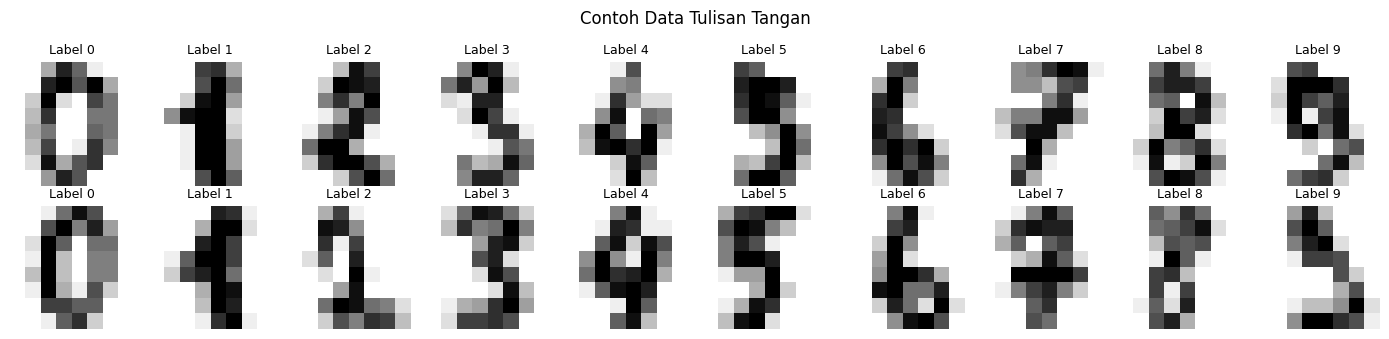

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))
for d in range(10):
    idx = np.where(y == d)[0][:2]
    for r, i in enumerate(idx):
        axes[r, d].imshow(images[i], cmap="gray_r")
        axes[r, d].set_title(f"Label {d}", fontsize=9)
        axes[r, d].axis("off")
plt.suptitle("Contoh Data Tulisan Tangan")
plt.tight_layout()
plt.show()

**2b. Distribusi kelas.** Kelas yang seimbang berarti akurasi dapat dipakai sebagai metrik utama tanpa perlu penanganan ketidakseimbangan data.

digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


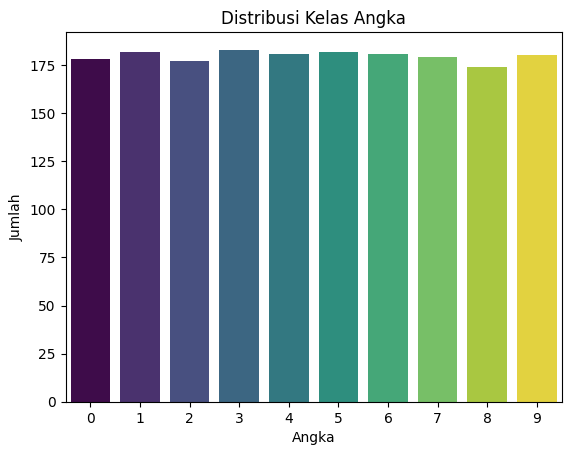

In [5]:
print(y.value_counts().sort_index())

sns.countplot(x=y, hue=y, palette="viridis", legend=False)
plt.title("Distribusi Kelas Angka")
plt.xlabel("Angka")
plt.ylabel("Jumlah")
plt.show()

**2c. Statistik dan pola intensitas piksel.** Peta panas di bawah menunjukkan area gambar yang paling sering terisi tinta. Piksel di bagian tepi cenderung kosong, sedangkan bagian tengah paling informatif.

Nilai piksel minimum: 0.0 | maksimum: 16.0


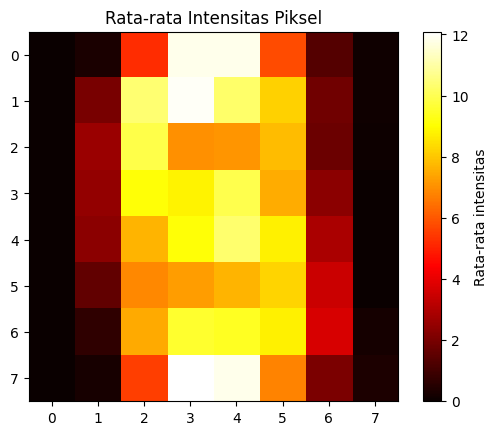

In [6]:
print("Nilai piksel minimum:", X.values.min(), "| maksimum:", X.values.max())

plt.imshow(X.mean().values.reshape(8, 8), cmap="hot")
plt.colorbar(label="Rata-rata intensitas")
plt.title("Rata-rata Intensitas Piksel")
plt.show()

### Tahap 3. Pra-pemrosesan Data
**Tujuan:** memastikan data bersih dan layak dipakai.

**3a. Pemeriksaan *missing value* dan duplikasi**

In [7]:
print("Total missing value :", X.isnull().sum().sum())
print("Jumlah data duplikat :", X.duplicated().sum())

Total missing value : 0
Jumlah data duplikat : 0


**3b. Penghapusan piksel tidak informatif.** Piksel yang bernilai sama pada semua gambar (varians nol) tidak membantu membedakan angka, sehingga dihapus.

In [8]:
piksel_konstan = X.columns[X.var() == 0]
print("Piksel dengan varians nol:", list(piksel_konstan))

X = X.drop(columns=piksel_konstan)
print("Jumlah fitur setelah dibersihkan:", X.shape[1])

Piksel dengan varians nol: ['pixel_0', 'pixel_32', 'pixel_39']
Jumlah fitur setelah dibersihkan: 61


### Tahap 4. Pembagian Data (80% Latih, 20% Uji)
**Tujuan:** memisahkan data untuk melatih model dan data untuk mengujinya pada data yang belum pernah dilihat. `stratify=y` menjaga proporsi tiap angka tetap sama pada kedua bagian, dan `random_state=42` membuat hasil dapat direproduksi.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Data latih:", X_train.shape[0], "| Data uji:", X_test.shape[0])
print("\nJumlah per kelas pada data uji:")
print(y_test.value_counts().sort_index().to_string())

Data latih: 1437 | Data uji: 360

Jumlah per kelas pada data uji:
digit
0    36
1    36
2    35
3    37
4    36
5    37
6    36
7    36
8    35
9    36


### Tahap 5. Normalisasi Fitur
**Tujuan:** menyamakan skala fitur (rata-rata 0, simpangan baku 1). SVM, KNN, dan Logistic Regression sensitif terhadap skala fitur. *Scaler* hanya di-*fit* pada **data latih**, lalu diterapkan ke data uji, agar tidak terjadi ***data leakage***.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Rata-rata :", X_train_scaled.mean().round(4))
print("Std       :", X_train_scaled.std().round(4))

Rata-rata : 0.0
Std       : 1.0


### Tahap 6. Pelatihan Model SVM
**Tujuan:** melatih SVM pada data latih, lalu mencari kombinasi `C` dan `gamma` terbaik.

**6a. Model dasar** dengan parameter bawaan sebagai titik awal.

In [11]:
svm = SVC(kernel="rbf", random_state=42)
svm.fit(X_train_scaled, y_train)
print("Akurasi data uji (model dasar):", round(svm.score(X_test_scaled, y_test), 4))

Akurasi data uji (model dasar): 0.975


**6b. Optimasi hyperparameter** dengan *Grid Search* dan *5-fold cross-validation*. Data latih dibagi menjadi 5 bagian, dan setiap kombinasi parameter diuji 5 kali secara bergantian. Dengan 3 × 3 = 9 kombinasi, total ada 45 percobaan pelatihan. Pemilihan parameter hanya memakai data latih, sehingga data uji tetap murni untuk evaluasi akhir.

In [12]:
param_grid = {
    "C": [1, 10, 100],
    "gamma": ["scale", 0.001, 0.01],
}

grid = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid,
                    cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("Parameter terbaik   :", grid.best_params_)
print("Akurasi CV terbaik  :", round(grid.best_score_, 4))
best_svm = grid.best_estimator_

Parameter terbaik   : {'C': 100, 'gamma': 0.01}
Akurasi CV terbaik  : 0.9833


### Tahap 7. Evaluasi Model
**Tujuan:** mengukur kinerja model terbaik pada data uji menggunakan akurasi, presisi, *recall*, F1-score, dan *confusion matrix*.

In [13]:
y_pred = best_svm.predict(X_test_scaled)

print("Akurasi          :", round(accuracy_score(y_test, y_pred), 4))
print("Presisi (macro)  :", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall (macro)   :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F1-score (macro) :", round(f1_score(y_test, y_pred, average="macro"), 4))
print()
print(classification_report(y_test, y_pred))

Akurasi          : 0.9833
Presisi (macro)  : 0.9839
Recall (macro)   : 0.9832
F1-score (macro) : 0.9832

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       1.00      1.00      1.00        37
           6       0.97      1.00      0.99        36
           7       0.95      1.00      0.97        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



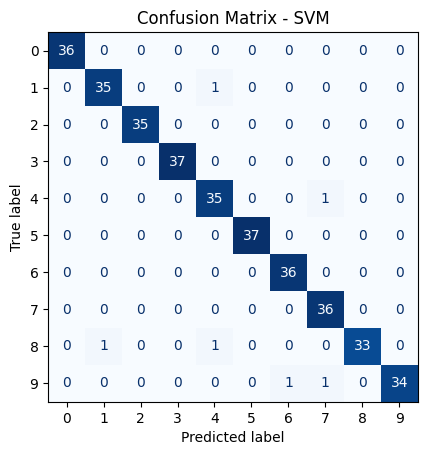

In [14]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - SVM")
plt.show()

### Tahap 8. Analisis Kesalahan Prediksi
**Tujuan:** melihat gambar mana yang salah dibaca dan angka mana yang sering tertukar, sebagai bahan evaluasi dan perbaikan model.

Jumlah salah prediksi: 6 dari 360


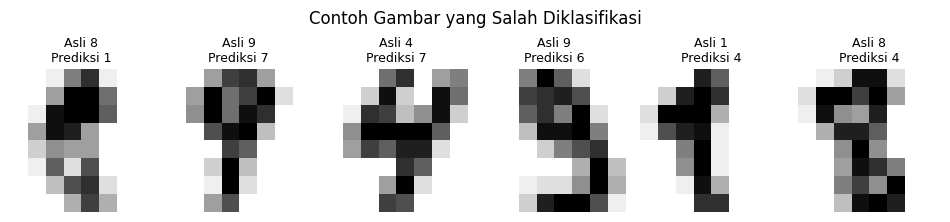

In [15]:
salah = np.where(y_pred != y_test.values)[0]
print("Jumlah salah prediksi:", len(salah), "dari", len(y_test))

if len(salah) > 0:
    n = min(len(salah), 10)
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.4), squeeze=False)
    for ax, k in zip(axes[0], salah[:n]):
        idx_asli = y_test.index[k]
        ax.imshow(images[idx_asli], cmap="gray_r")
        ax.set_title(f"Asli {y_test.values[k]}\nPrediksi {y_pred[k]}", fontsize=9)
        ax.axis("off")
    plt.suptitle("Contoh Gambar yang Salah Diklasifikasi")
    plt.tight_layout()
    plt.show()

In [16]:
# Pasangan angka yang tertukar
pasangan = Counter((int(a), int(b)) for a, b in zip(y_test.values, y_pred) if a != b)
for (asli, pred), n in pasangan.most_common():
    print(f"Angka {asli} salah dibaca sebagai {pred}: {n} kali")

Angka 8 salah dibaca sebagai 1: 1 kali
Angka 9 salah dibaca sebagai 7: 1 kali
Angka 4 salah dibaca sebagai 7: 1 kali
Angka 9 salah dibaca sebagai 6: 1 kali
Angka 1 salah dibaca sebagai 4: 1 kali
Angka 8 salah dibaca sebagai 4: 1 kali


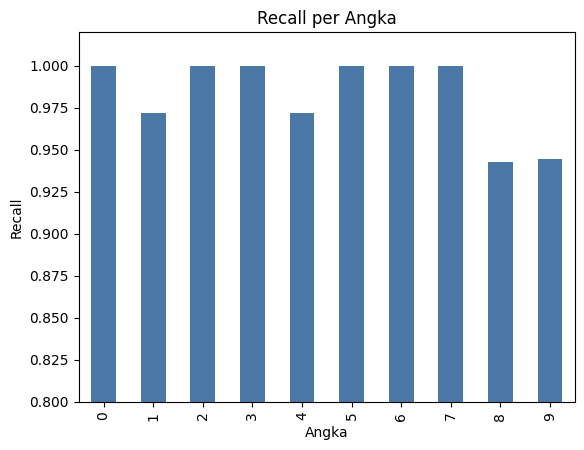

In [17]:
# Recall (tingkat keberhasilan mengenali) per angka
recall_per_kelas = pd.Series(recall_score(y_test, y_pred, average=None), index=range(10))
recall_per_kelas.plot(kind="bar", color="#4C78A8")
plt.ylim(0.8, 1.02)
plt.title("Recall per Angka")
plt.xlabel("Angka")
plt.ylabel("Recall")
plt.show()

### Tahap 9. Perbandingan dengan Model Lain
**Tujuan:** memastikan pilihan SVM memang layak, dengan membandingkannya terhadap empat metode lain pada data latih dan data uji yang sama. SVM, KNN, dan Logistic Regression memakai data yang sudah dinormalisasi, sedangkan model berbasis pohon tidak memerlukannya.

In [18]:
models = {
    "SVM (tuned)": (best_svm, X_train_scaled, X_test_scaled),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42), X_train, X_test),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), X_train, X_test),
    "KNN": (KNeighborsClassifier(n_neighbors=5), X_train_scaled, X_test_scaled),
    "Logistic Regression": (LogisticRegression(max_iter=2000), X_train_scaled, X_test_scaled),
}

hasil = []
for nama, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    p = model.predict(Xte)
    hasil.append({"Model": nama,
                  "Akurasi": accuracy_score(y_test, p),
                  "Presisi": precision_score(y_test, p, average="macro"),
                  "Recall": recall_score(y_test, p, average="macro"),
                  "F1-score": f1_score(y_test, p, average="macro")})

df_hasil = pd.DataFrame(hasil).set_index("Model").sort_values("Akurasi", ascending=False)
df_hasil.round(4)

,Akurasi,Presisi,Recall,F1-score
Model,,,,
SVM (tuned),0.9833,0.9839,0.9832,0.9832
Random Forest,0.9722,0.9729,0.9718,0.9718
Logistic Regression,0.9722,0.9721,0.9719,0.9719
KNN,0.9639,0.9646,0.9637,0.9634
Decision Tree,0.8306,0.8307,0.8298,0.8295


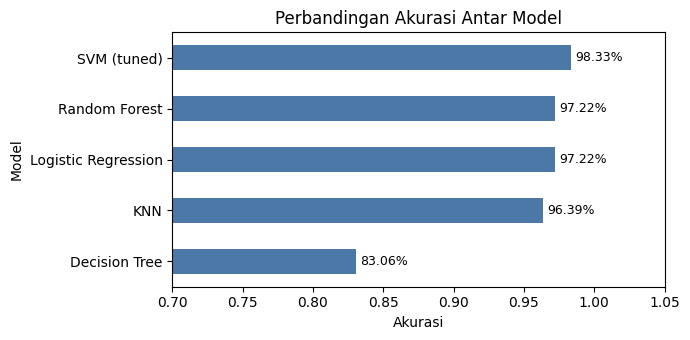

In [19]:
ax = df_hasil["Akurasi"].sort_values().plot(kind="barh", color="#4C78A8", figsize=(7, 3.5))
for i, v in enumerate(df_hasil["Akurasi"].sort_values()):
    ax.text(v + 0.003, i, f"{v:.2%}", va="center", fontsize=9)
ax.set_xlim(0.7, 1.05)
plt.title("Perbandingan Akurasi Antar Model")
plt.xlabel("Akurasi")
plt.tight_layout()
plt.show()

### Tahap 10. Contoh Penggunaan Model (Demo Prediksi)
**Tujuan:** menunjukkan bagaimana model yang sudah dilatih dipakai untuk membaca gambar angka baru. Pada sistem nyata, langkah inilah yang dijalankan otomatis untuk setiap angka pada dokumen.

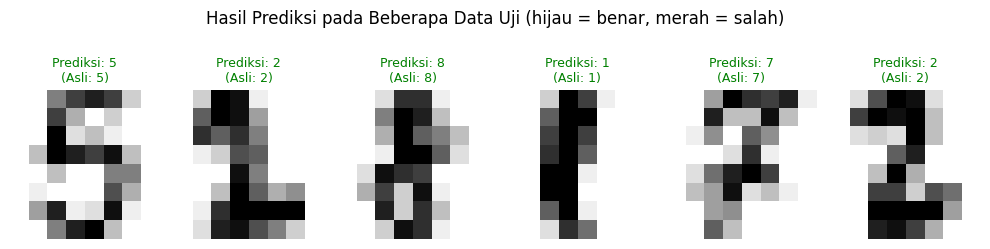

In [20]:
fig, axes = plt.subplots(1, 6, figsize=(10, 2.2))
for ax, k in zip(axes, range(6)):
    idx_asli = y_test.index[k]
    pred = best_svm.predict(X_test_scaled[k].reshape(1, -1))[0]
    ax.imshow(images[idx_asli], cmap="gray_r")
    warna = "green" if pred == y_test.values[k] else "red"
    ax.set_title(f"Prediksi: {pred}\n(Asli: {y_test.values[k]})", color=warna, fontsize=9)
    ax.axis("off")
plt.suptitle("Hasil Prediksi pada Beberapa Data Uji (hijau = benar, merah = salah)", y=1.12)
plt.tight_layout()
plt.show()

## 5. Hasil dan Pembahasan

> Angka di bawah diperoleh dari eksekusi notebook ini dengan `random_state=42` (scikit-learn 1.8.0). Jika dijalankan ulang dengan versi library atau `random_state` yang berbeda, angkanya dapat bergeser sedikit.

### 5.1 Hasil optimasi SVM
- Model SVM dasar (parameter bawaan) mencapai akurasi **97,50%** pada data uji.
- Hasil *Grid Search* memilih **C = 100** dan **gamma = 0,01**, dengan akurasi *cross-validation* **98,33%**.
- Model terbaik mencapai akurasi **98,33%** pada data uji. Optimasi hyperparameter menaikkan akurasi sekitar 0,8 poin persentase.

### 5.2 Kinerja model terbaik pada data uji (360 gambar)

| Metrik | Nilai |
|---|---|
| Akurasi | 98,33% |
| Presisi (macro) | 0,9839 |
| Recall (macro) | 0,9832 |
| F1-score (macro) | 0,9832 |

Dari 360 gambar uji, **354 dikenali dengan benar dan 6 salah**. Angka 0, 2, 3, 5, 6, dan 7 seluruhnya dikenali dengan benar (recall 1,00).

### 5.3 Perbandingan dengan model lain

| Model | Akurasi | Presisi | Recall | F1-score |
|---|---|---|---|---|
| **SVM (tuned)** | **0,9833** | **0,9839** | **0,9832** | **0,9832** |
| Random Forest | 0,9722 | 0,9729 | 0,9718 | 0,9718 |
| Logistic Regression | 0,9722 | 0,9721 | 0,9719 | 0,9719 |
| KNN | 0,9639 | 0,9646 | 0,9637 | 0,9634 |
| Decision Tree | 0,8306 | 0,8307 | 0,8298 | 0,8295 |

### 5.4 Pembahasan
1. **SVM memberikan hasil terbaik** pada semua metrik. Hal ini sesuai dengan sifat data, yaitu berdimensi tinggi dan memiliki batas antarkelas yang tidak linear, sehingga cocok dengan kernel RBF.
2. **Decision Tree tunggal jauh tertinggal** (sekitar 83%), sedangkan Random Forest yang menggabungkan banyak pohon naik ke sekitar 97%. Ini menunjukkan keunggulan metode *ensemble* dibanding satu pohon keputusan yang cenderung *overfitting*.
3. **Kesalahan yang terjadi** hanya 6 gambar, yaitu angka 8 dibaca sebagai 1 dan 4, angka 9 dibaca sebagai 7 dan 6, angka 4 dibaca sebagai 7, dan angka 1 dibaca sebagai 4. Angka 8 dan 9 memiliki *recall* terendah (sekitar 0,94). Pola ini wajar karena pada resolusi 8×8 bentuk angka-angka tersebut memang bisa tampak mirip, terutama jika tulisannya tidak rapi.
4. **Tidak ada indikasi *overfitting* yang berarti**, karena akurasi *cross-validation* pada data latih (98,33%) sejalan dengan akurasi pada data uji (98,33%).
5. Dengan akurasi sekitar 98%, masih ada kira-kira 1 sampai 2 kesalahan untuk setiap 100 angka. Pada aplikasi yang berisiko tinggi seperti nominal cek, hasil model sebaiknya tetap disertai verifikasi manusia untuk kasus yang meragukan.

## 6. Manfaat

| Pihak | Manfaat |
|---|---|
| **Layanan pos** | Kode pos pada amplop dibaca otomatis dan surat dipilah secara massal dengan cepat, sehingga mengurangi surat salah alamat. |
| **Perbankan** | Nominal angka pada cek dan formulir setoran dapat dibaca otomatis, sehingga mempercepat proses kliring dan mengurangi risiko salah input manual. |
| **Instansi pemerintah dan perusahaan** | Digitalisasi formulir dan arsip tulisan tangan (nomor identitas, tanggal, jumlah) menjadi lebih cepat dan murah. |
| **Operasional** | Biaya tenaga kerja input data berkurang, dan petugas dapat berfokus pada kasus yang butuh penilaian manusia. |
| **Akurasi dan konsistensi** | Model tidak lelah dan menerapkan standar yang sama pada setiap dokumen. |
| **Pengembangan ilmu** | Pengenalan digit menjadi dasar bagi pengenalan tulisan (*OCR*) yang lebih luas, termasuk huruf dan aksara daerah. |

Sistem pengenalan tulisan tangan serupa telah dipakai secara nyata untuk membaca kode pos dan cek bank (LeCun dkk., 1989; LeCun dkk., 1998).

## 7. Keterbatasan dan Pengembangan

**Keterbatasan penelitian ini:**
- Gambar hanya berukuran **8×8 piksel**, hasil penyederhanaan dari gambar asli 32×32. Pada sistem nyata, resolusi dan detail gambar lebih tinggi.
- Data uji dalam dataset ini berasal dari **13 penulis** pada formulir terstruktur. Tulisan di dunia nyata jauh lebih beragam, misalnya pada kertas kusam, tinta pudar, atau angka yang menempel.
- Evaluasi memakai satu kali pembagian data 80:20. Hasil yang lebih kokoh dapat diperoleh dengan *cross-validation* penuh.
- Ruang pencarian *Grid Search* sengaja dibuat kecil agar cepat dijalankan.

**Pengembangan yang mungkin dilakukan:**
- Memakai ***Convolutional Neural Network (CNN)*** pada gambar beresolusi lebih tinggi, seperti dataset MNIST (28×28 piksel), yang menjadi standar pengenalan digit modern.
- Menambah teknik *data augmentation* (rotasi, pergeseran, penebalan goresan) untuk meningkatkan ketahanan model.
- Menambahkan ambang kepercayaan (*confidence threshold*): prediksi dengan keyakinan rendah diteruskan ke petugas untuk diperiksa.
- Memperluas ke pengenalan huruf dan teks tulisan tangan.

## 8. Kesimpulan

1. Pengenalan angka tulisan tangan adalah permasalahan klasifikasi multikelas (10 kelas) yang nyata dan bernilai praktis, terutama untuk pemilahan surat dan pembacaan cek bank.
2. Metode **Support Vector Machine dengan kernel RBF** yang dioptimalkan dengan *Grid Search* dan *cross-validation* menghasilkan **akurasi 98,33%** pada 360 data uji, dengan F1-score (macro) 0,9832.
3. SVM mengungguli Random Forest (97,22%), Logistic Regression (97,22%), KNN (96,39%), dan Decision Tree (83,06%) pada dataset ini.
4. Kesalahan yang tersisa sangat sedikit (6 dari 360) dan terjadi pada angka yang bentuknya memang mirip. Untuk penerapan berisiko tinggi, tetap diperlukan verifikasi manusia.
5. Hasil ini menunjukkan bahwa Machine Learning dapat mengotomatisasi pekerjaan baca-ketik yang berulang dengan cepat dan akurat.

## 9. Sumber Data dan Daftar Pustaka

### Sumber data
- Alpaydin, E., & Kaynak, C. (1998). *Optical Recognition of Handwritten Digits* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50P49 (halaman dataset: https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits). Lisensi CC BY 4.0.
- Salinan data uji tersedia melalui fungsi `sklearn.datasets.load_digits` pada scikit-learn. Dokumentasi: https://scikit-learn.org/stable/datasets/toy_dataset.html#optical-recognition-of-handwritten-digits-dataset

### Daftar pustaka
- Alpaydin, E., & Kaynak, C. (1998). Cascading classifiers. *Kybernetika, 34*(4), 369–374.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297.
- Garris, M. D., Blue, J. L., Candela, G. T., Dimmick, D. L., Geist, J., Grother, P. J., Janet, S. A., & Wilson, C. L. (1994). *NIST Form-Based Handprint Recognition System* (NISTIR 5469). National Institute of Standards and Technology.
- Kaynak, C. (1995). *Methods of Combining Multiple Classifiers and Their Applications to Handwritten Digit Recognition* [Master's thesis]. Institute of Graduate Studies in Science and Engineering, Bogazici University.
- LeCun, Y., Boser, B., Denker, J. S., Henderson, D., Howard, R. E., Hubbard, W., & Jackel, L. D. (1989). Backpropagation applied to handwritten zip code recognition. *Neural Computation, 1*(4), 541–551.
- LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE, 86*(11), 2278–2324.
- Pedregosa, F., dkk. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.